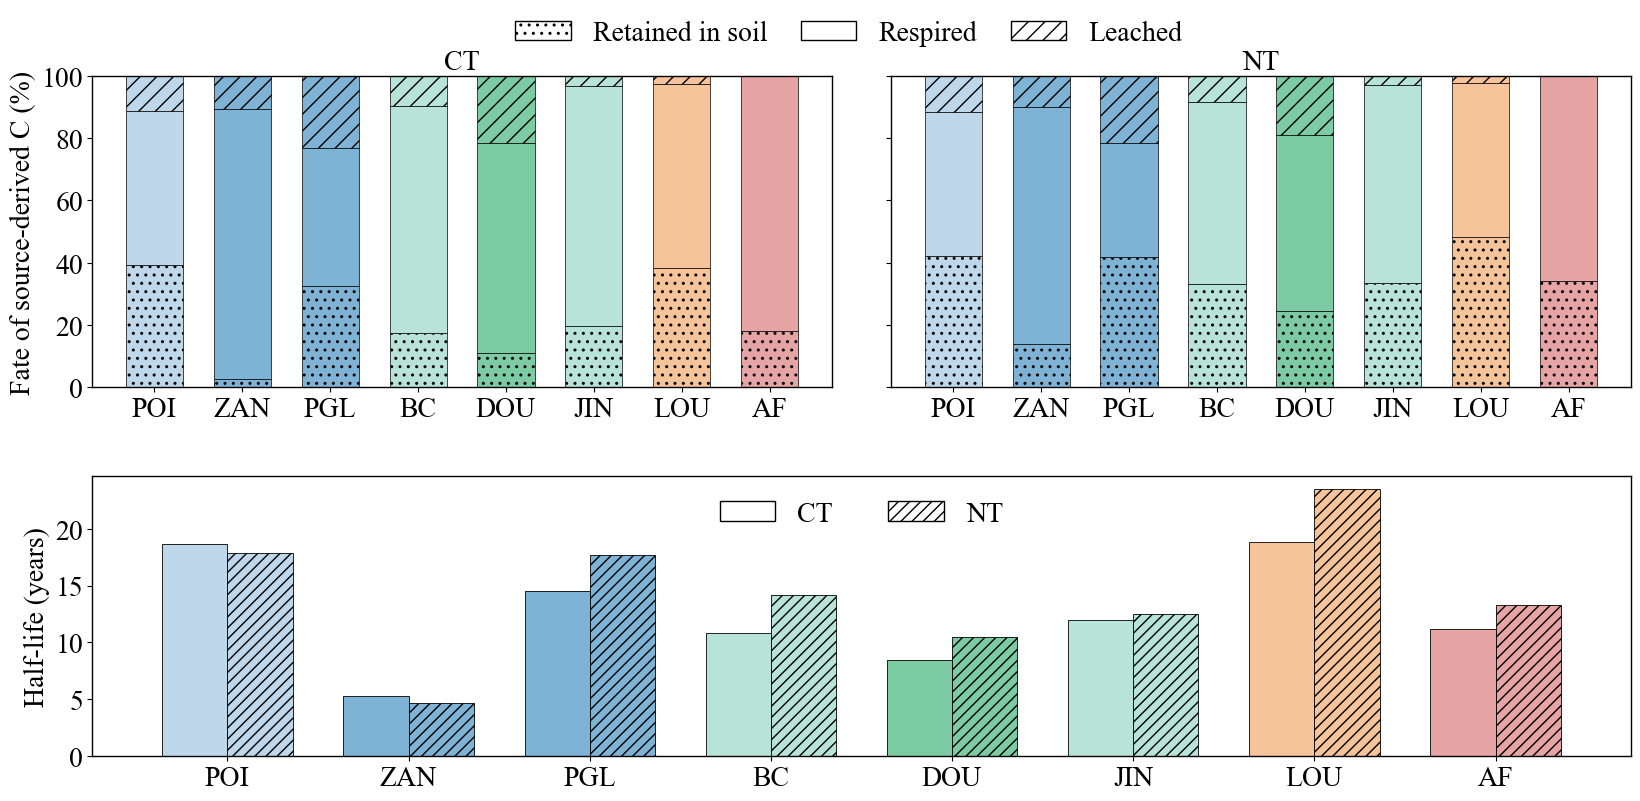

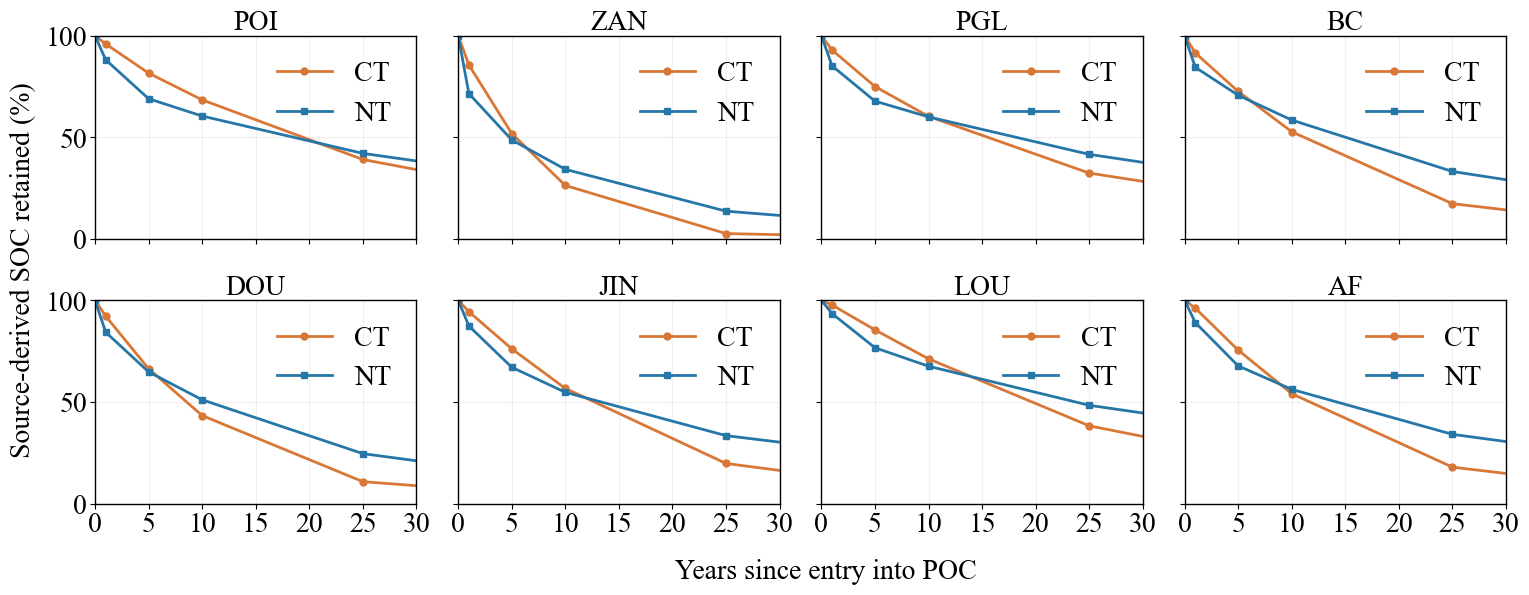

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# SETTINGS
folder = Path('Results_SourceFlux')
sites = ['POI', 'ZAN', 'PGL', 'BC', 'DOU', 'JIN', 'LOU', 'AF']
years = [0, 1, 5, 10, 25, 50, 100]
year, save = 25, False

figsize_fate = (17, 8.5)
figsize_retention = (17, 6.5)
tick_font, label_font, title_font, legend_font = 20, 20, 20, 20

ct_color, nt_color = '#D97736', '#2677A8'
site_colors = {'AF':'#E6A4A4', 'BC':'#B8E3D8', 'DOU':'#7CCBA2', 'JIN':'#B8E3D8', 'LOU':'#F6C49B', 'POI':'#BFD7EA', 'PGL':'#7FB3D5', 'ZAN':'#7FB3D5'}

plt.rcParams.update({'font.family':'serif', 'font.serif':['Times New Roman','DejaVu Serif'], 'axes.linewidth':1})

# READ DATA
fate = pd.read_csv(folder / 'Fate.csv')
summary = pd.read_csv(folder / 'Summary.csv')
fate = fate[fate.Site.isin(sites)].merge(summary[['Site','Treatment','Label']], on=['Site','Treatment'], validate='many_to_one')

if not np.allclose(fate.SOC + fate.L + fate.Respired + fate.Leached, fate.Label, atol=1e-8):
    raise ValueError('Carbon balance failed')

if not np.allclose(fate.SOC, fate[['A','POM','MAOM','DOC','B']].sum(axis=1), atol=1e-8):
    raise ValueError('Soil pool sum failed')

for col in ['SOC','L','Respired','Leached']:
    fate[col+'_pct'] = 100*fate[col]/fate.Label

data = fate[np.isclose(fate.Year, year)].copy()
retention = fate[fate.Year.isin(years)].copy()
x = np.arange(len(sites))
colors = [site_colors[s] for s in sites]

# =====================================================
# FIGURE 1: SOURCE-DERIVED CARBON FATE AND AGE-ALIGNED HALF-LIFE
# =====================================================
fig = plt.figure(figsize=figsize_fate)
gs = fig.add_gridspec(2, 2, height_ratios=[1, .9], hspace=.30, wspace=.08)

columns = ['SOC','Respired','Leached']
names = ['Retained in soil','Respired','Leached']
hatches = ['..','','//']

for col, treatment in enumerate(['CT','NT']):
    ax = fig.add_subplot(gs[0,col])
    values = data[data.Treatment == treatment].set_index('Site').loc[sites]
    bottom = np.zeros(len(sites))

    for column, hatch in zip(columns, hatches):
        heights = values[column+'_pct'].to_numpy()
        ax.bar(x, heights, .65, bottom=bottom, color=colors, edgecolor='black', linewidth=.5, hatch=hatch)
        bottom += heights

    ax.set_title(treatment, fontsize=title_font, pad=5)
    ax.set_xticks(x, sites)
    ax.set_ylim(0,100)
    ax.tick_params(axis='both', labelsize=tick_font, pad=3)

    if col == 0:
        ax.set_ylabel('Fate of source-derived C (%)', fontsize=label_font)
    else:
        ax.tick_params(axis='y', labelleft=False)

handles = [Patch(facecolor='white', edgecolor='black', hatch=h, label=n) for n,h in zip(names,hatches)]
fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(.52,.985), ncol=3, frameon=False, fontsize=legend_font, columnspacing=1.2)

# HALF-LIFE
ax = fig.add_subplot(gs[1,:])
width = .36

for treatment, offset, hatch in [('CT',-width/2,''),('NT',width/2,'///')]:
    values = summary[summary.Treatment == treatment].set_index('Site')
    half_life = values.loc[sites,'Half_life'].to_numpy()
    valid = np.isfinite(half_life)
    positions = x+offset

    ax.bar(positions[valid], half_life[valid], width, color=np.array(colors)[valid], edgecolor='black', linewidth=.6, hatch=hatch)

    for i in np.flatnonzero(~valid):
        ax.text(positions[i], .03, f'{treatment}: beyond horizon', rotation=90, transform=ax.get_xaxis_transform(), ha='center', va='bottom', fontsize=12)

ax.set_xticks(x,sites)
ax.set_ylabel('Half-life (years)',fontsize=label_font)
#ax.set_xlabel('Sites',fontsize=label_font, labelpad=4)
ax.tick_params(axis='both',labelsize=tick_font,pad=3)
ax.set_ylim(bottom=0)

half_handles = [Patch(facecolor='white',edgecolor='black',label='CT'), Patch(facecolor='white',edgecolor='black',hatch='///',label='NT')]
ax.legend(handles=half_handles,loc='upper center',bbox_to_anchor=(.5,1.0),ncol=2,fontsize=legend_font,frameon=False)

fig.subplots_adjust(left=.075,right=.98,bottom=.09,top=.89)

if save:
    (folder/'Plots').mkdir(exist_ok=True)
    fig.savefig(folder/'Plots'/'Carbon_Fate_HalfLife.png',dpi=300,bbox_inches='tight')

plt.show()
plt.close(fig)

# =====================================================
# FIGURE 2: AGE-ALIGNED SITE-WISE SOC RETENTION
# =====================================================
fig, axes = plt.subplots(2,4,figsize=figsize_retention,sharex=True,sharey=True)
fig.subplots_adjust(left=.07,right=0.9,bottom=.14,top=.86,wspace=.13,hspace=.30)

for ax, site in zip(axes.flat,sites):
    
    sub = retention[retention.Site == site]
    for treatment,color,marker in [('CT',ct_color,'o'),('NT',nt_color,'s')]:
        d = sub[sub.Treatment == treatment].sort_values('Year')
        ax.plot(d.Year,d.SOC_pct,marker=marker,color=color,linewidth=2,markersize=5,label=treatment)

    ax.set_title(site,fontsize=title_font,pad=4)
    ax.set_xlim(0,30)
    ax.set_ylim(0,100)
    ax.set_xticks([0,5,10,15,20,25,30])
    ax.tick_params(axis='both',labelsize=tick_font,pad=2)
    ax.legend(loc='upper right', fontsize=legend_font, frameon=False)
    ax.grid(alpha=.2)

fig.supxlabel('Years since entry into POC',fontsize=label_font,y=.015)
fig.supylabel('Source-derived SOC retained (%)',fontsize=label_font,x=.02)

if save:
    (folder/'Plots').mkdir(exist_ok=True)
    fig.savefig(folder/'Plots'/'SOC_Retention_Sites.png',dpi=300,bbox_inches='tight')

plt.show()
plt.close(fig)